# EDA na Prática — Student Performance & Study Habits Dataset

**Aluno:** Luis Guilherme Alves Lauria Soares
**Dataset:** [Student Performance & Study Habits Dataset](https://www.kaggle.com/datasets/harshadapatil31/student-performance-and-study-habits-dataset) (Harshada Patil, Kaggle, licença CC0)

Sobre o dataset: 1.000 registros de estudantes, com hábitos de estudo (horas de estudo, frequência), fatores de estilo de vida (sono, atividades extracurriculares, trabalho de meio período), dados demográficos (gênero, escolaridade dos pais) e desempenho acadêmico (nota da prova final e conceito por letra).

## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     
COR_CONTEXTO = "#e9d4d0"     
COR_DESTAQUE = "#2d223a"    
COR_ALERTA = "tab:red"       

In [2]:
from pathlib import Path

RAIZ = Path("..")  
df = pd.read_csv(RAIZ / "data" / "raw" / "student_performance_dataset.csv")
df_raw = df.copy()  
df.head()

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o dataset tem 12 colunas — um identificador (`student_id`), variáveis de hábito de estudo/estilo de vida (`study_time_hours`, `attendance_percent`, `sleep_hours`, `extracurricular_activities`, `part_time_job`), demográficas (`gender`, `parental_education`, `internet_access`) e de desempenho (`previous_grade`, `final_exam_score`, `final_grade`). Quantas dessas 12 vocês esperam que sejam quantitativas e quantas qualitativas, só pelo nome?

### Dimensão e Tipos de Dados

In [3]:
df.shape


(1000, 12)

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   object 
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          898 non-null    object 
 6   internet_access             1000 non-null   object 
 7   extracurricular_activities  1000 non-null   object 
 8   part_time_job               1000 non-null   object 
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   object 
dtypes: float64(5), int64(1), object(6)
memory usage: 93.9+ KB


In [5]:
df.describe()


,student_id,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,3.570700,85.092300,6.799500,69.740900,83.543500
std,288.819436,1.478559,9.270685,1.203527,12.613425,10.341333
min,1.000000,0.500000,54.800000,3.200000,31.300000,46.800000
25%,250.750000,2.600000,78.800000,5.900000,61.000000,76.075000
50%,500.500000,3.600000,85.200000,6.800000,69.600000,83.800000
75%,750.250000,4.500000,91.900000,7.600000,78.400000,91.525000
max,1000.000000,8.100000,100.000000,10.000000,100.000000,100.000000


### Duplicadas

In [6]:
df.duplicated().sum()


np.int64(0)

**Discussão:** como `student_id` deveria ser único por aluno, uma duplicata "de verdade" nesse dataset é mais bem verificada olhando só essa coluna (duas linhas podem ser parecidas em todo o resto por coincidência, mas não deveriam repetir o mesmo id).

In [7]:
df["student_id"].duplicated().sum()


np.int64(0)

### Padronização de nomes de colunas

**Passo não executado, com justificativa:** no notebook de referência (Heart Disease) foi necessário renomear o atributo-alvo (`num`) porque o nome original não era autoexplicativo. Aqui isso não é necessário: as colunas já vêm em `snake_case` e com nomes descritivos (`study_time_hours`, `attendance_percent`, `final_exam_score` etc.), então não há renomeação de colunas a fazer.

### Criando uma variável de resultado (desempenho alto / baixo)

Assim como no notebook de referência simplificamos o alvo original (`num`, 0–4) para uma variável binária (`doenca_cardiaca`), aqui vamos derivar uma variável binária `situacao` para facilitar comparações visuais ao longo do notebook (convenção de cor: rosa = Alto, roxo = Baixo).

**Justificativa da escolha:** a primeira ideia seria usar o conceito `F` de `final_grade` como "reprovado", mas isso resultou em uma classe com pouquíssimos alunos (menos de 2% da base) — desbalanceamento forte demais pra sustentar comparações visuais ao longo do notebook. Por isso, `situacao` é definida por um corte na mediana de `final_exam_score`: quem está acima da mediana é "Desempenho Alto", quem está abaixo é "Desempenho Baixo". Isso garante os dois grupos igualmente representados (~50/50) e ainda é interpretável (alunos com nota acima vs. abaixo do "aluno típico" da turma).

In [8]:
mediana_nota_final = df["final_exam_score"].median()
df["situacao"] = np.where(df["final_exam_score"] >= mediana_nota_final, "Desempenho Alto", "Desempenho Baixo")
df["situacao"].value_counts()


situacao
Desempenho Alto     501
Desempenho Baixo    499
Name: count, dtype: int64

## 2. Dados Faltantes

In [9]:
df.isna().sum()


student_id                      0
gender                          0
study_time_hours                0
attendance_percent              0
sleep_hours                     0
parental_education            102
internet_access                 0
extracurricular_activities      0
part_time_job                   0
previous_grade                  0
final_exam_score                0
final_grade                     0
situacao                        0
dtype: int64

**Discussão:** alguma feature tem dados ausentes?

**Resposta:** Resposta: Sim, uma feature tem dados ausentes: parental_education, com 102 valores faltantes em 1.000 linhas (10,2% da base). As demais 11 colunas não têm nenhum valor ausente.

Como há ausentes, a seção "Identificando o mecanismo de dados ausentes" logo abaixo se aplica normalmente — não precisa usar a nota de justificativa de pular (essa é só pro caso de nenhuma coluna ter ausente).

> **Nota:** se nenhuma coluna tiver ausentes no dataset de vocês, a seção "Identificando o mecanismo de dados ausentes" logo abaixo não se aplica — ela só faz sentido quando existem valores faltantes para investigar. Registrem isso como a justificativa para pular essa etapa, caso seja o caso.

### Identificando o mecanismo de dados ausentes

Contar ausentes por coluna não conta a história toda: se a ausência estiver relacionada a outras variáveis (ou ao próprio valor que falta), isso muda a estratégia de tratamento. Comparamos, abaixo, as médias das variáveis quantitativas e a distribuição de outras variáveis qualitativas entre linhas com e sem ausência, pra ver se o "perfil" de quem tem o dado faltante é diferente do restante.

In [10]:
COL_COM_AUSENTES = "parental_education"  
ausente = df[COL_COM_AUSENTES].isna()
cols_quant_provisorio = ["study_time_hours", "attendance_percent", "sleep_hours", "previous_grade", "final_exam_score"]

print(f"Linhas com {COL_COM_AUSENTES} ausente: {ausente.sum()} ({ausente.mean():.1%})")

comparacao_ausencia = pd.DataFrame({
    "media_quando_ausente": df.loc[ausente, cols_quant_provisorio].mean(),
    "media_quando_presente": df.loc[~ausente, cols_quant_provisorio].mean(),
}).round(2)
comparacao_ausencia["diferenca"] = (comparacao_ausencia["media_quando_ausente"] - comparacao_ausencia["media_quando_presente"]).round(2)
comparacao_ausencia


Linhas com parental_education ausente: 102 (10.2%)


,media_quando_ausente,media_quando_presente,diferenca
study_time_hours,3.63,3.56,0.07
attendance_percent,86.02,84.99,1.03
sleep_hours,6.72,6.81,-0.09
previous_grade,70.61,69.64,0.97
final_exam_score,83.44,83.56,-0.12


In [11]:
print(pd.crosstab(ausente, df["gender"], normalize="index").round(3))
print()
print(pd.crosstab(ausente, df["final_grade"], normalize="index").round(3))


gender              Female   Male
parental_education               
False                0.516  0.484
True                 0.461  0.539

final_grade             A      B      C      D      F
parental_education                                   
False               0.284  0.356  0.258  0.089  0.012
True                0.284  0.333  0.284  0.088  0.010


Relembrando:
- **MCAR:** mecanismo aleatório, sem viés — a ausência não depende de nada (nem de outras variáveis, nem do próprio valor).
- **MAR:** a ausência depende de outras variáveis observadas, mas não do próprio valor ausente — vieses possíveis de corrigir.
- **MNAR:** a ausência depende do próprio valor que está faltando.

Resposta: As médias e proporções ficam bem parecidas entre quem tem e quem não tem parental_education ausente (diferenças pequenas, ex: 0,07 em study_time_hours, 0,97 em previous_grade; distribuição de final_grade quase idêntica). Isso aponta pra MCAR — não achei relação clara entre a ausência e nenhuma outra variável ou o desempenho do aluno. Não dá pra confirmar 100% só com os dados, mas o padrão sugere ausência aleatória.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes/outliers), calculamos as estatísticas descritivas e olhamos as distribuições. Esse retrato "antes" orienta as decisões de tratamento da próxima seção.

In [12]:
VARS_QUANT = ["study_time_hours", "attendance_percent", "sleep_hours", "previous_grade", "final_exam_score"]
VARS_QUALI = ["gender", "parental_education", "internet_access", "extracurricular_activities", "part_time_job", "final_grade"]

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)


,mean,median,std,min,max,skewness,kurtosis
study_time_hours,3.57,3.60,1.48,0.50,8.10,0.12,-0.34
attendance_percent,85.09,85.20,9.27,54.80,100.00,-0.34,-0.26
sleep_hours,6.80,6.80,1.20,3.20,10.00,-0.02,-0.22
previous_grade,69.74,69.60,12.61,31.30,100.00,0.00,-0.24
final_exam_score,83.54,83.80,10.34,46.80,100.00,-0.22,-0.51


**Pra discutir:** olhando a tabela, alguma variável já parece assimétrica (skewness acima de 1 em módulo) ou com cauda pesada (kurtosis acima de 2 em módulo)? Isso é coerente com o que vocês esperariam (ex: `study_time_hours` tende a ter mais alunos estudando pouco do que muito, puxando a cauda direita)?

**Resposta:** Não. Todas as variáveis ficaram com skewness entre -0,34 e 0,12 e kurtosis entre -0,51 e -0,22 — bem abaixo dos limites de 1 e 2. Não é o que eu esperava (achei que study_time_hours puxaria pra direita), mas a distribuição saiu simétrica em todas, provavelmente por ser um dataset simulado.

### Distribuições de dados

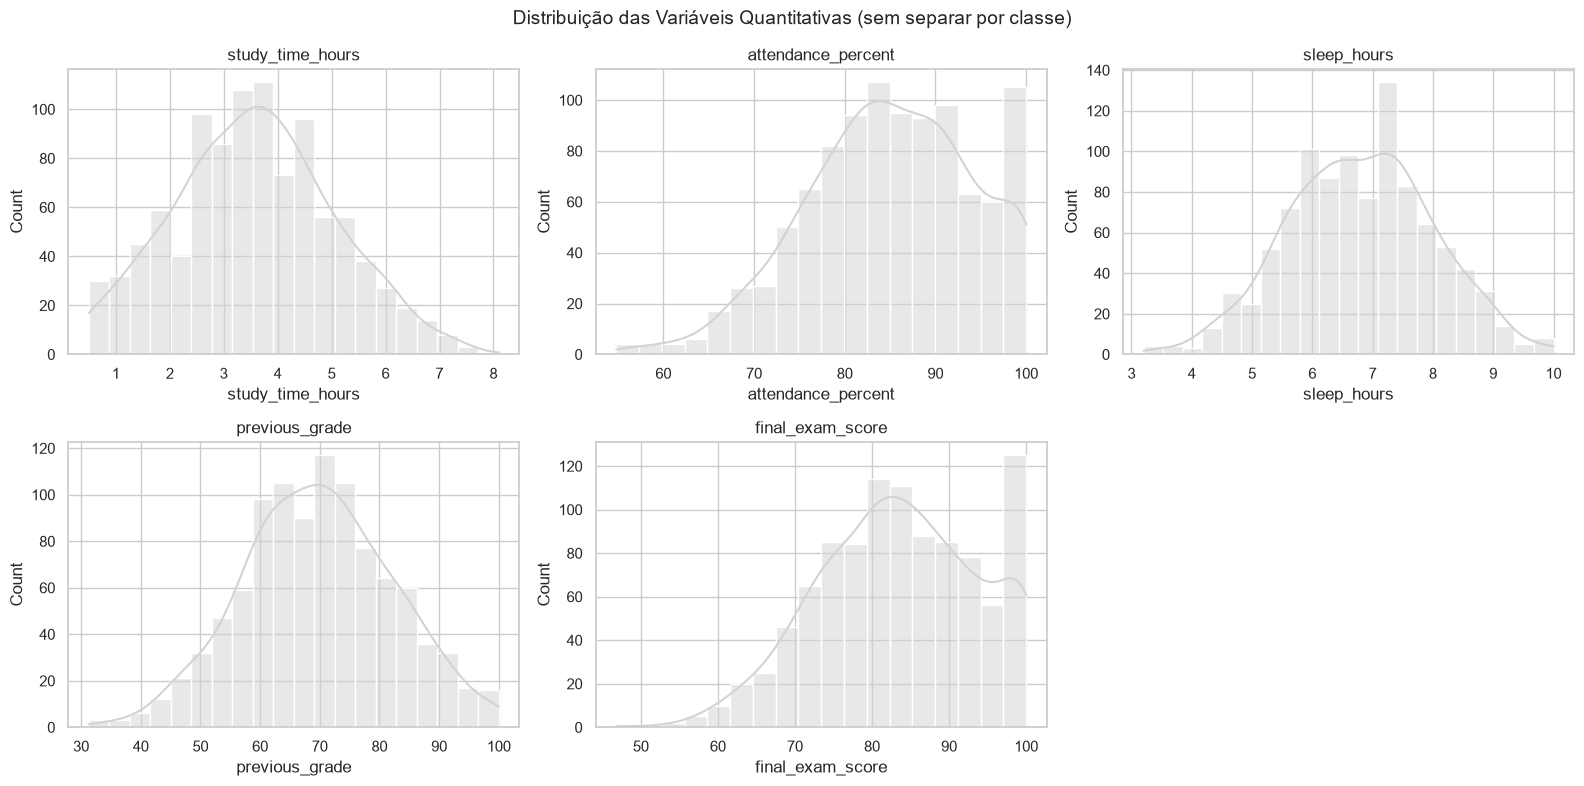

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()


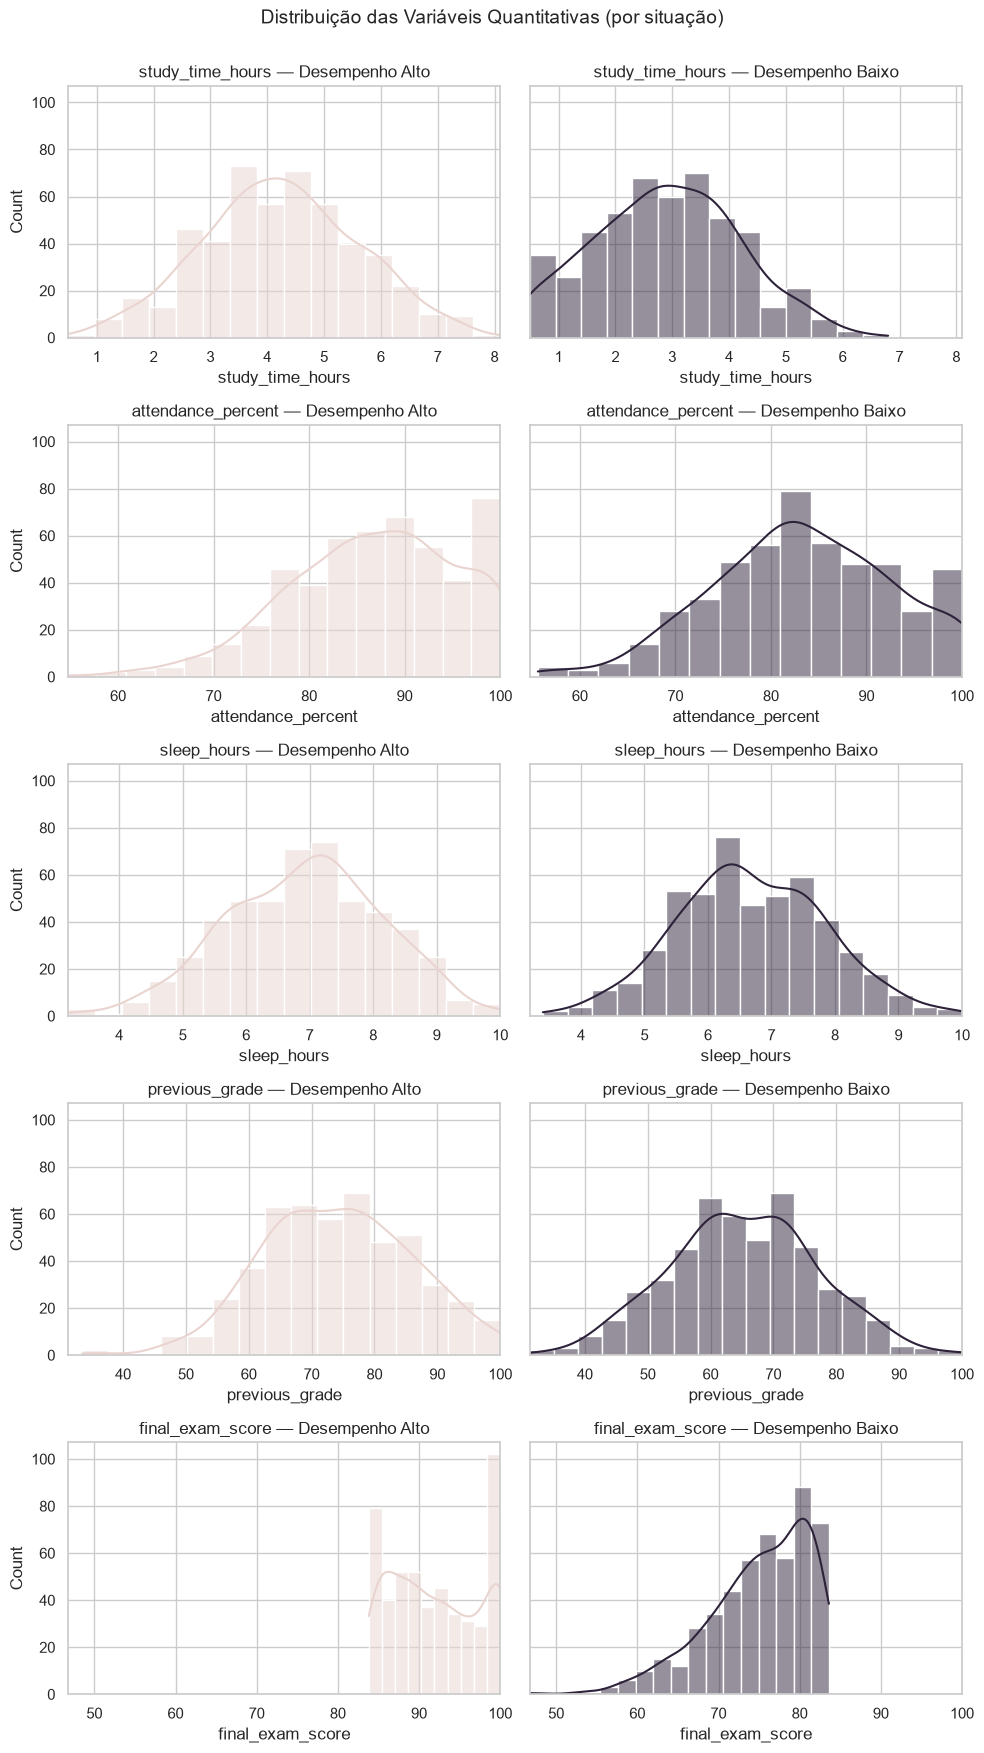

In [14]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Desempenho Alto", COR_CONTEXTO), ("Desempenho Baixo", COR_DESTAQUE)]):
        subset = df[df["situacao"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas (por situação)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()


**Pra discutir:** com as classes em painéis separados (mesma escala de eixo X em cada linha), alguma variável parece ter formato bem diferente entre "Desempenho Alto" e "Desempenho Baixo"?

**Resposta:** Sim, principalmente study_time_hours (média 4,24h no grupo Alto vs. 2,90h no Baixo) e previous_grade (74,25 vs. 65,21) — os painéis desses dois ficam visivelmente deslocados um em relação ao outro. attendance_percent mostra uma diferença menor (86,8 vs. 83,4) e sleep_hours fica quase igual (6,92 vs. 6,68) — praticamente sobreposto entre as duas classes.

### Teste de Aderência (normalidade)

In [15]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")


,estatistica,p_valor,rejeita_normalidade
variavel,,,
study_time_hours,0.9935,0.000247,True
attendance_percent,0.9787,0.000000,True
sleep_hours,0.9977,0.175638,False
previous_grade,0.9973,0.099874,False
final_exam_score,0.9772,0.000000,True


**Como afirmar o resultado:** quando o teste rejeita H0 (p < 0.05), a afirmação correta é "temos evidência estatística contra a normalidade" — uma conclusão forte. "Não podemos garantir normalidade" é o que cabe quando o teste **não** rejeita H0, já que ausência de rejeição nunca prova normalidade, só que não há evidência suficiente contra.

**Pra discutir:** quais variáveis rejeitam normalidade? Isso muda quais técnicas (paramétricas x não-paramétricas) seriam mais adequadas para essas variáveis mais adiante?

**Resposta:** Rejeitam normalidade (p < 0,05): study_time_hours, attendance_percent e final_exam_score. Não rejeitam: sleep_hours e previous_grade. Isso indica que, pra análises envolvendo as três primeiras, técnicas não-paramétricas (Spearman em vez de Pearson, Mann-Whitney/Kruskal-Wallis em vez de teste-t/ANOVA) seriam mais adequadas — embora, como vimos, o Shapiro-Wilk fica bem sensível com n=1000, então essa rejeição pode refletir desvios pequenos, não necessariamente distribuições muito diferentes de uma normal.

### Medidas de Tendência Central

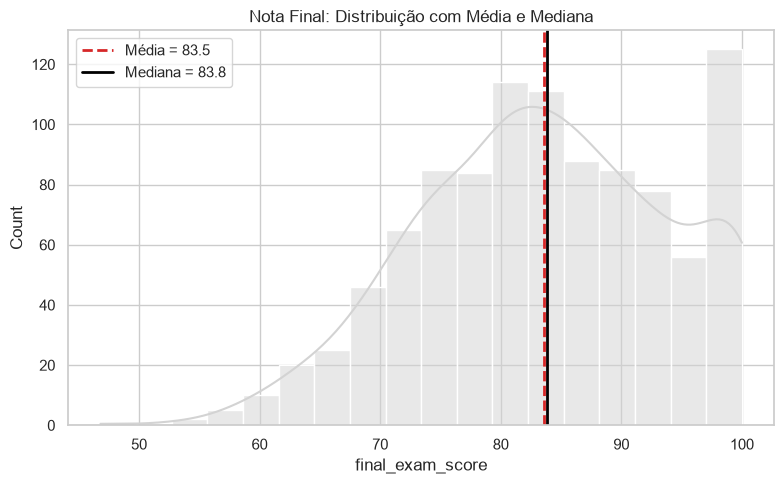

In [16]:
media_nota = df["final_exam_score"].mean()
mediana_nota = df["final_exam_score"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="final_exam_score", kde=True, color=COR_NEUTRA)
plt.axvline(media_nota, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_nota:.1f}")
plt.axvline(mediana_nota, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_nota:.1f}")
plt.title("Nota Final: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()


### Dispersão

In [17]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)


,var,std,IQR
study_time_hours,2.19,1.48,1.90
attendance_percent,85.95,9.27,13.10
sleep_hours,1.45,1.20,1.70
previous_grade,159.10,12.61,17.40
final_exam_score,106.94,10.34,15.45


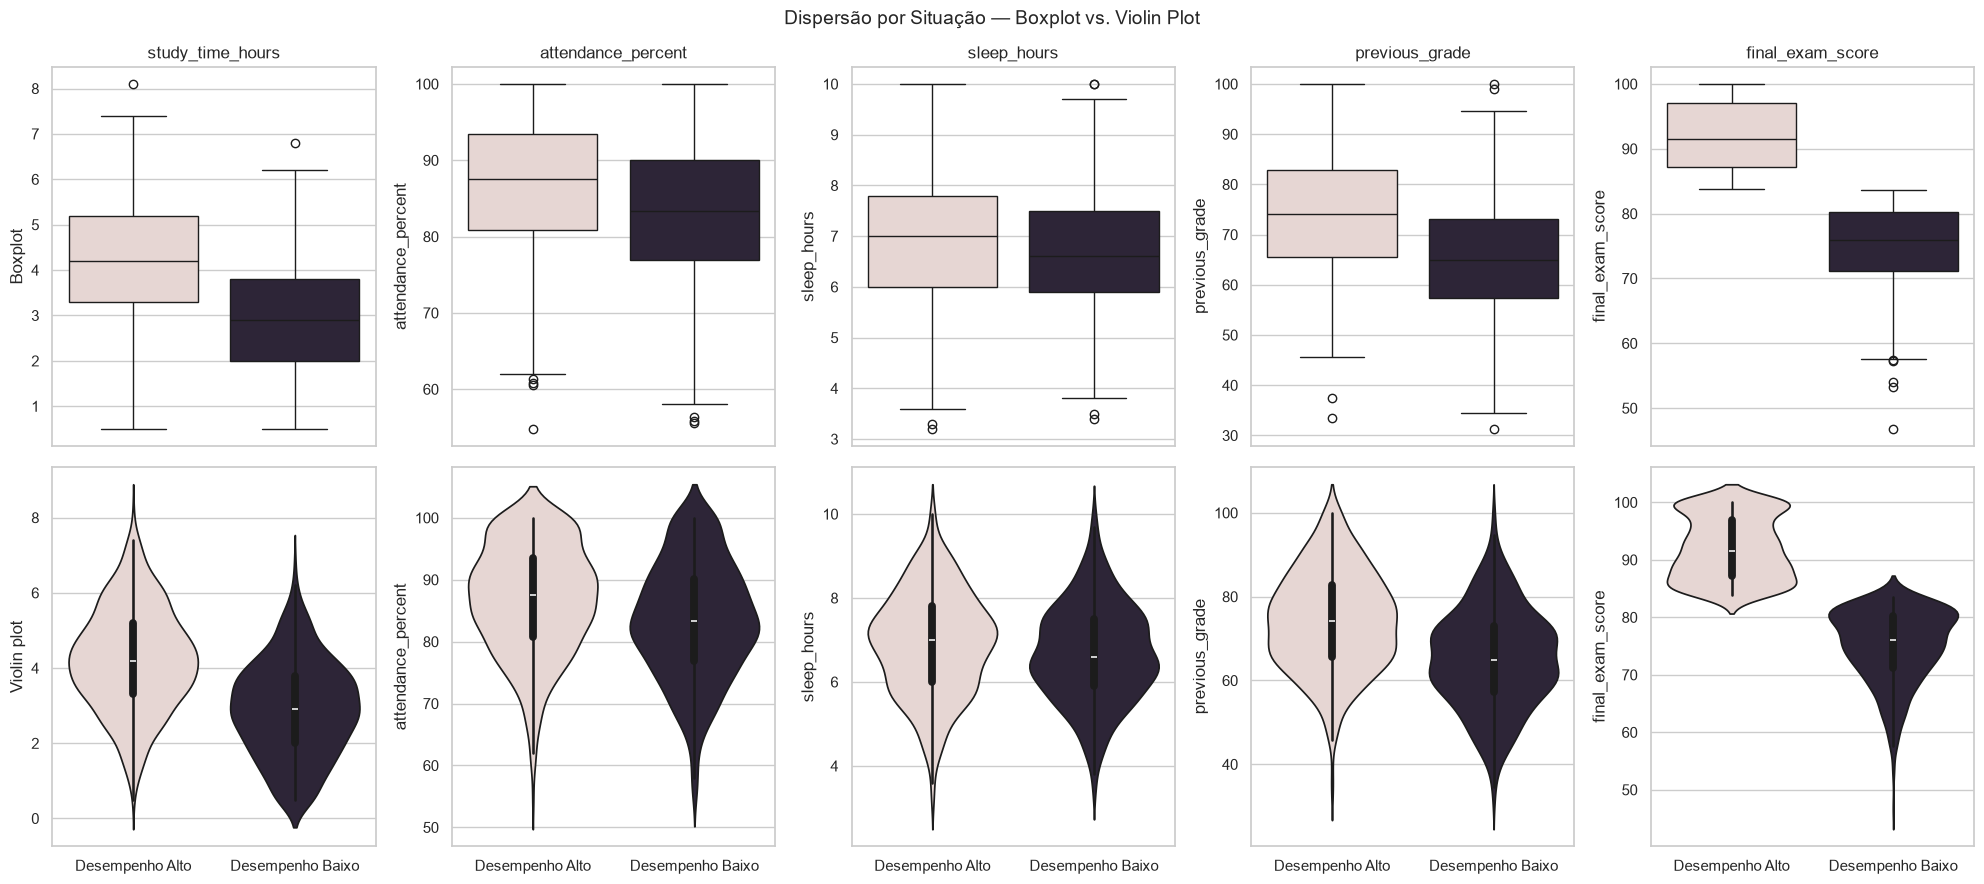

In [18]:
palette_situacao = {"Desempenho Alto": COR_CONTEXTO, "Desempenho Baixo": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="situacao", y=col, hue="situacao",
                palette=palette_situacao, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="situacao", y=col, hue="situacao",
                    palette=palette_situacao, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Situação — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()


**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente diferente entre "Desempenho Alto" e "Desempenho Baixo"? Isso já é um indício, antes mesmo da análise bivariada formal, de que essa variável pode ajudar a diferenciar as duas situações.

**Resposta:** O tamanho do IQR (largura da caixa) fica parecido entre os dois grupos em todas as variáveis — a diferença nítida é na posição da caixa, não no tamanho: study_time_hours (caixa de 3,3–5,2 no Alto vs. 2,0–3,8 no Baixo) e previous_grade (65,6–82,8 vs. 57,3–73,0) têm caixas bem deslocadas, sem sobreposição total. attendance_percent e sleep_hours têm caixas parecidas em largura e com bastante sobreposição entre os grupos. Isso confirma o mesmo indício de antes: study_time_hours e previous_grade são as que mais devem ajudar a diferenciar Alto de Baixo.

## 4. Tratamento de Dados Ausentes e Outliers

Com o retrato "antes" (Seção 3) em mãos, temos a informação que faltava para decidir como tratar dados ausentes (se houver) e outliers das variáveis quantitativas.

### Detecção de Outliers por IQR

In [19]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T


,limite_inferior,limite_superior,n_outliers
study_time_hours,-0.25,7.35,4.0
attendance_percent,59.15,111.55,6.0
sleep_hours,3.35,10.15,2.0
previous_grade,34.90,104.50,3.0
final_exam_score,52.90,114.70,1.0


### Visualizando os Outliers

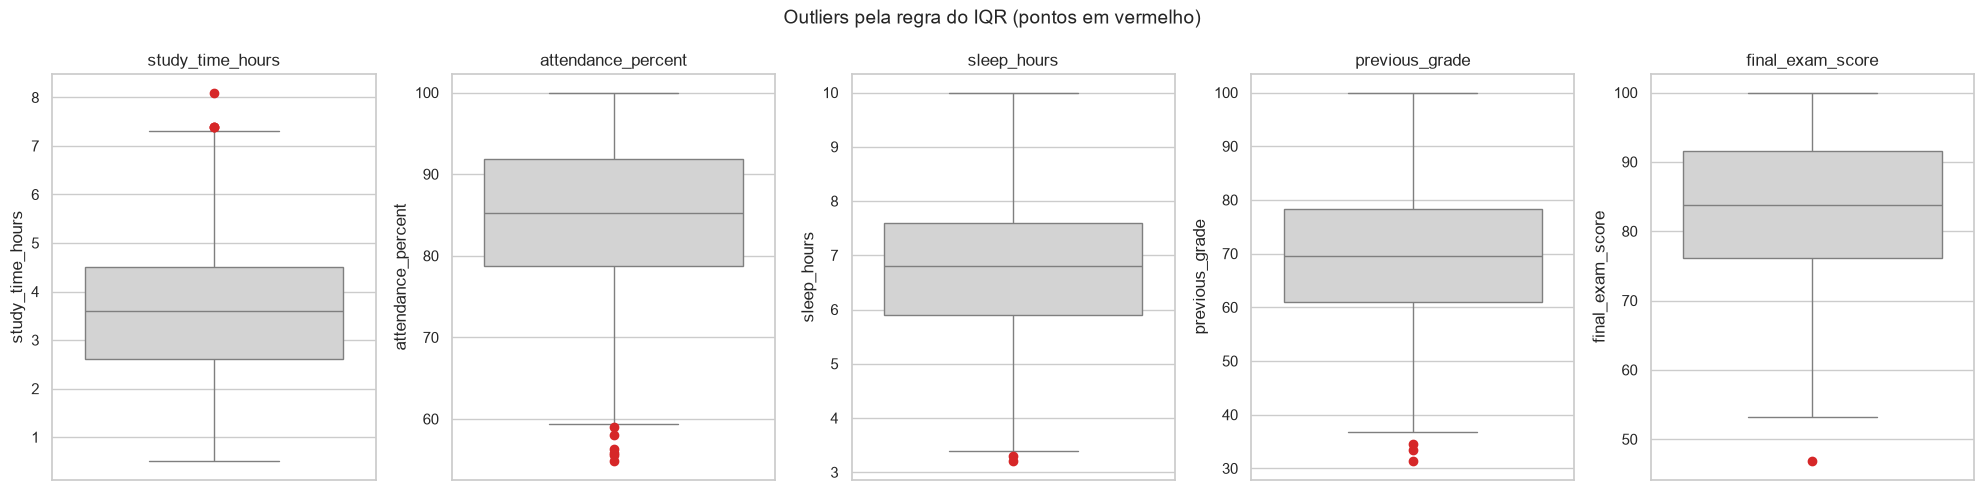

In [20]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()


**Pra discutir:** classificando os outliers encontrados nos três tipos vistos em aula (estatístico/legítimo, de domínio, erro de dados) — os valores extremos aqui (ex: alunos com pouquíssimas horas de sono, ou frequência muito baixa) parecem plausíveis (manter/transformar) ou violam algum limite físico/lógico conhecido (investigar)? Isso muda a decisão de manter, transformar ou remover.

**Resposta:** Todos parecem plausíveis, do tipo estatístico/legítimo — nada viola limite físico ou lógico. sleep_hours mínimo é 3,2–3,3h (pouco, mas fisiologicamente possível); study_time_hours máximo é 7,4–8,1h/dia (alto, mas plausível pra um aluno dedicado); attendance_percent mínimo é 54,8–59% (frequência baixa, mas dentro da escala 0–100); previous_grade mínimo 31,3–34,5 e final_exam_score mínimo 46,8 (notas baixas, mas válidas). Nenhum é erro de dado (não há valor negativo, nem acima de 100% ou de 24h). Decisão: manter todos, sem transformar ou remover.

Dados ausentes: parental_education tem 10,2% de valores ausentes, com padrão indicando MCAR (visto na seção anterior). Como o volume não é pequeno o suficiente pra descartar sem perda relevante (102 linhas), a decisão é imputar com a categoria explícita "Não informado", preservando o tamanho da amostra sem inventar uma categoria real.

Outliers: conforme discutido, todos os outliers encontrados (em study_time_hours, attendance_percent, sleep_hours, previous_grade, final_exam_score) são estatísticos/legítimos, sem violar nenhum limite físico ou lógico. Decisão: manter todos os valores como estão, sem transformar ou remover nada.

In [21]:
df_antes = df.copy()

if COL_COM_AUSENTES in df.columns and df[COL_COM_AUSENTES].isna().any():
    df[COL_COM_AUSENTES] = df[COL_COM_AUSENTES].fillna("Não informado")

print(f"Linhas antes: {df_antes.shape[0]} | Linhas depois: {df.shape[0]}")
print(f"Ausentes em {COL_COM_AUSENTES} antes: {df_antes[COL_COM_AUSENTES].isna().sum()} | depois: {df[COL_COM_AUSENTES].isna().sum()}")


Linhas antes: 1000 | Linhas depois: 1000
Ausentes em parental_education antes: 102 | depois: 0


### Exportando os dados para o dashboard

Salva o dataset original (`data/raw/`) e o tratado (`data/clean/dataset.csv`), que é o arquivo lido pelo `app.py`.

In [22]:
# Exporta os dados para o app Streamlit (o notebook está em notebooks/, a raiz fica um nível acima)
(RAIZ / "data" / "raw").mkdir(parents=True, exist_ok=True)
(RAIZ / "data" / "clean").mkdir(parents=True, exist_ok=True)

df_raw.to_csv(RAIZ / "data" / "raw" / "dataset_raw.csv", index=False)
df.to_csv(RAIZ / "data" / "clean" / "dataset.csv", index=False)

print("RAIZ aponta para:", RAIZ.resolve())
print("tratado salvo em:", (RAIZ / "data" / "clean" / "dataset.csv").resolve(), df.shape)

RAIZ aponta para: C:\Users\luisgx\Desktop\AVD-20262-pratica-streamlit-main
tratado salvo em: C:\Users\luisgx\Desktop\AVD-20262-pratica-streamlit-main\data\clean\dataset.csv (1000, 13)


## 5. Estatística Descritiva pt 2 (antes x depois)

In [23]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)


,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
study_time_hours,0.121,0.121,-0.340,-0.340,0.0,0.0
attendance_percent,-0.337,-0.337,-0.261,-0.261,0.0,0.0
sleep_hours,-0.023,-0.023,-0.218,-0.218,0.0,0.0
previous_grade,0.001,0.001,-0.238,-0.238,0.0,0.0
final_exam_score,-0.219,-0.219,-0.511,-0.511,0.0,0.0


**Pra discutir:** os valores mudaram muito entre "antes" e "depois"? Se a

*   Item de lista
*   Item de lista

decisão da Seção 4 foi não remover nada, isso é esperado (as tabelas devem ficar idênticas) — registrem essa constatação como parte da justificativa, em vez de tratá-la como um erro.

**Resposta:** Não, os valores de skewness e kurtosis ficaram idênticos entre "antes" e "depois" (delta = 0 em tudo). Isso é esperado: a única mudança feita na Seção 4 foi imputar parental_education (uma variável categórica, que nem entra nessas contas), e nenhum outlier ou linha das variáveis quantitativas foi removido. Ou seja, a tabela idêntica confirma que o tratamento foi conservador, e não um erro no cálculo.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas — Frequências

In [24]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))



--- gender ---
        absoluta  relativa
gender                    
Female       510      0.51
Male         490      0.49

--- parental_education ---
                    absoluta  relativa
parental_education                    
High School              356     0.356
Bachelors                308     0.308
Masters                  184     0.184
Não informado            102     0.102
PhD                       50     0.050

--- internet_access ---
                 absoluta  relativa
internet_access                    
Yes                   854     0.854
No                    146     0.146

--- extracurricular_activities ---
                            absoluta  relativa
extracurricular_activities                    
Yes                              572     0.572
No                               428     0.428

--- part_time_job ---
               absoluta  relativa
part_time_job                    
No                  684     0.684
Yes                 316     0.316

--- final_grade ---
  

### Visualizando as frequências

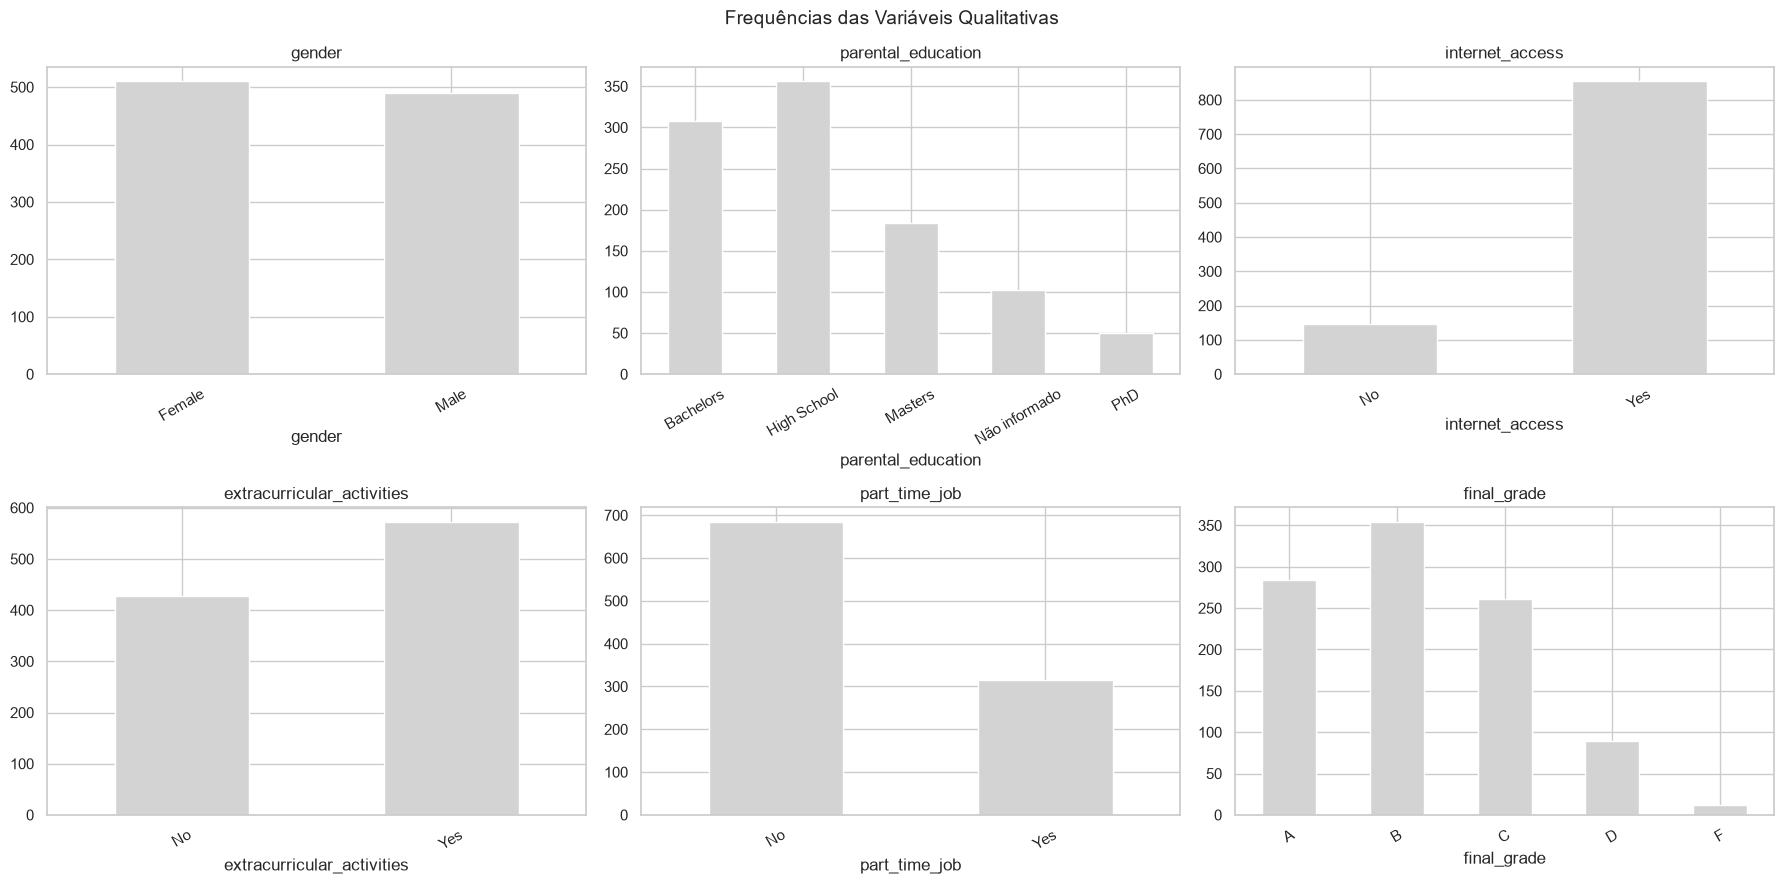

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=30)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()


**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como interpretamos cruzamentos com essa variável na análise bivariada.

**Resposta:** Sim, final_grade é a mais desbalanceada (razão 29,5, entropia 0,835) — "F" tem só 1,2% dos alunos. internet_access também pesa pra um lado (85,4% "Yes", razão 5,85). As demais (gender, extracurricular_activities, part_time_job, parental_education) são mais equilibradas. Isso importa porque cruzamentos envolvendo final_grade (especialmente a categoria "F") vão ter poucas observações pra sustentar conclusões.

### Desbalanceamento entre Classes

In [26]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["situacao"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T


,n_classes,razao_desbalanceamento,entropia_normalizada
gender,2.0,1.04,1.000
parental_education,5.0,7.12,0.885
internet_access,2.0,5.85,0.600
extracurricular_activities,2.0,1.34,0.985
part_time_job,2.0,2.16,0.900
final_grade,5.0,29.50,0.835
situacao,2.0,1.00,1.000


**Pra discutir:** alguma variável está com entropia próxima de 0 (bem desbalanceada)? E a própria `situacao` (aprovado/reprovado) — está balanceada o suficiente para não distorcer a análise bivariada?

**Resposta:** Nenhuma chega perto de 0. A mais baixa é internet_access (0,6), seguida de final_grade (0,835) e parental_education (0,885); gender, extracurricular_activities e situacao ficam entre 0,9 e 1,0. A própria situacao tem entropia 1,0 (501 "Desempenho Alto" vs. 499 "Desempenho Baixo") — perfeitamente balanceada, não distorce a bivariada.

### Análise Bivariada

> Conforme o post da atividade, os testes estatísticos formais (chi-quadrado, Mann-Whitney etc.) são **opcionais** nesta entrega — a análise abaixo é feita de forma visual/descritiva.

#### Quantitativa x Quantitativa — Correlação

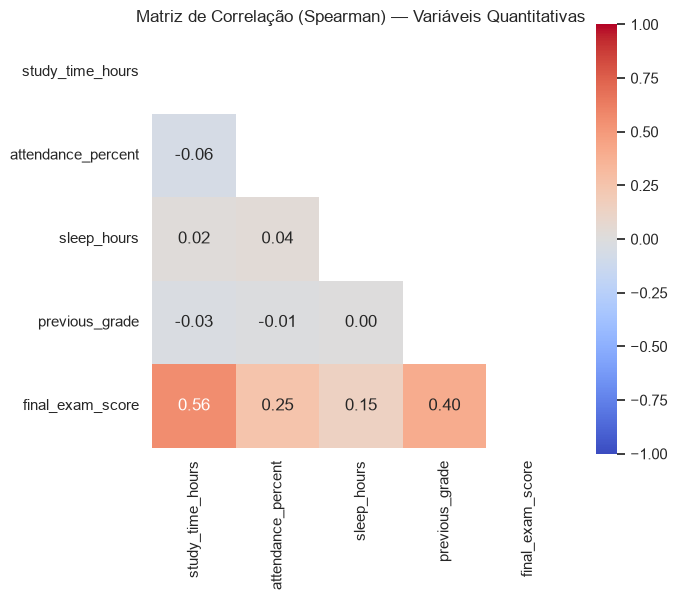

In [27]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")

mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
plt.figure(figsize=(7, 6))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.grid(False)
plt.tight_layout()
plt.show()


**Como interpretar:** |r| < 0.3 ~ fraca, 0.3 < |r| < 0.7 ~ moderada, |r| > 0.7 ~ forte.

**Pra discutir:** alguma correlação chama atenção por ser forte (ex: `study_time_hours` x `final_exam_score`)? Faz sentido do ponto de vista de domínio?

**Resposta:** A correlação mais forte é study_time_hours x final_exam_score (r = 0,56, moderada), seguida de previous_grade x final_exam_score (0,40) e attendance_percent x final_exam_score (0,25, fraca). Nenhuma chega a "forte" (>0,7). Faz sentido do ponto de vista de domínio: estudar mais horas e ter tido notas boas antes tende a se refletir na nota final, mas nenhuma variável isolada explica o desempenho sozinha

#### Dispersão (scatter) entre duas variáveis quantitativas

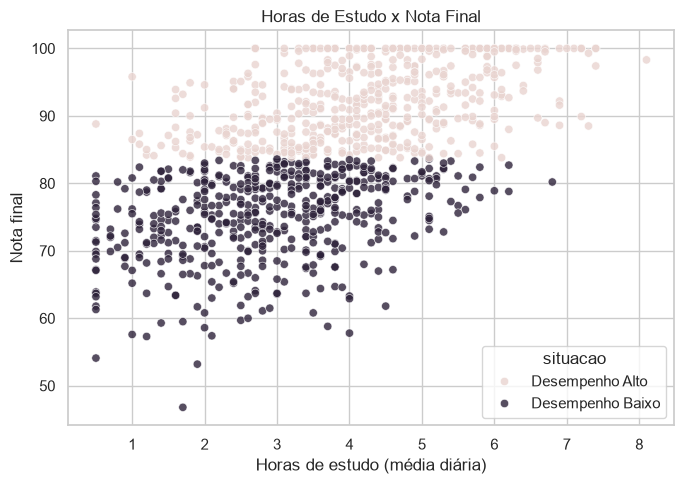

In [28]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="study_time_hours", y="final_exam_score", hue="situacao",
                palette=palette_situacao, alpha=0.8)
plt.title("Horas de Estudo x Nota Final")
plt.xlabel("Horas de estudo (média diária)")
plt.ylabel("Nota final")
plt.tight_layout()
plt.show()


**Pra discutir:** existe uma tendência visível (mais horas de estudo, nota mais alta)? As duas situações ocupam regiões diferentes do gráfico, ou estão misturadas?

**Resposta:** Sim, dá pra ver uma tendência de subida (mais horas de estudo, nota mais alta), coerente com a correlação moderada de 0,56. Mas as duas situações não ficam totalmente separadas — há bastante sobreposição no meio do gráfico, com pontos "Desempenho Alto" e "Baixo" misturados na faixa intermediária de horas de estudo; a separação fica mais clara só nos extremos (poucas horas → quase só Baixo; muitas horas → quase só Alto).

#### Quantitativa x Qualitativa — Comparando Grupos

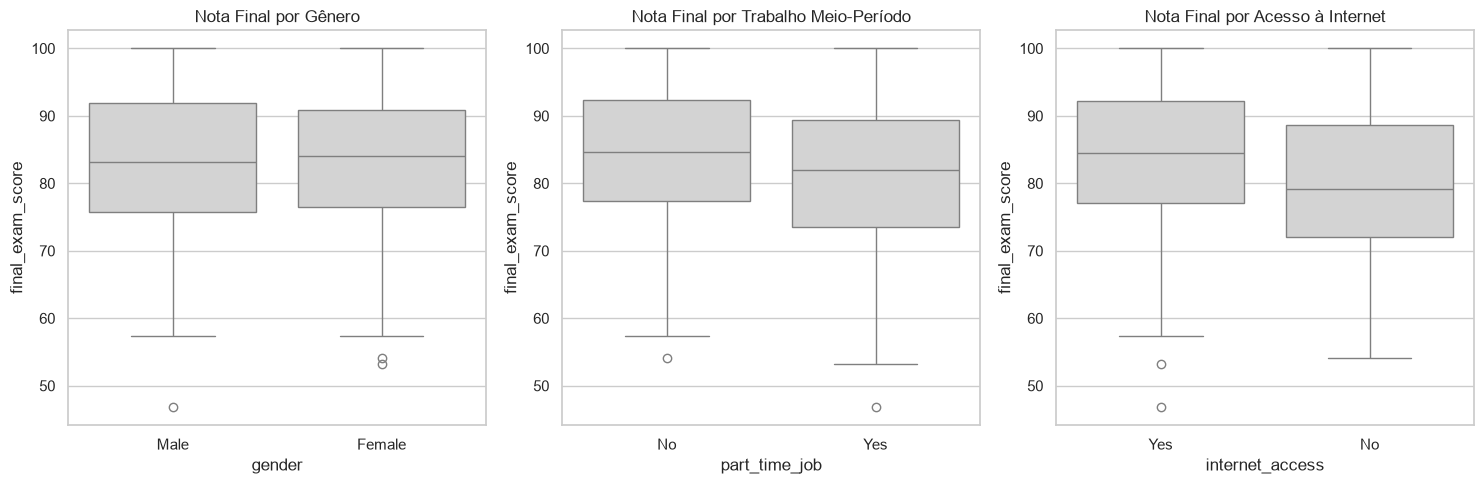

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(data=df, x="gender", y="final_exam_score", color=COR_NEUTRA, ax=axes[0])
axes[0].set_title("Nota Final por Gênero")

sns.boxplot(data=df, x="part_time_job", y="final_exam_score", color=COR_NEUTRA, ax=axes[1])
axes[1].set_title("Nota Final por Trabalho Meio-Período")

sns.boxplot(data=df, x="internet_access", y="final_exam_score", color=COR_NEUTRA, ax=axes[2])
axes[2].set_title("Nota Final por Acesso à Internet")

plt.tight_layout()
plt.show()


**Pra discutir:** algum desses grupos mostra uma diferença nítida na nota final? Lembrem que "parecer diferente" no boxplot não substitui um teste formal — mas como esses testes são opcionais nesta entrega, tratem essa leitura como indício, não como conclusão estatisticamente confirmada.

### Avaliação de Fairness

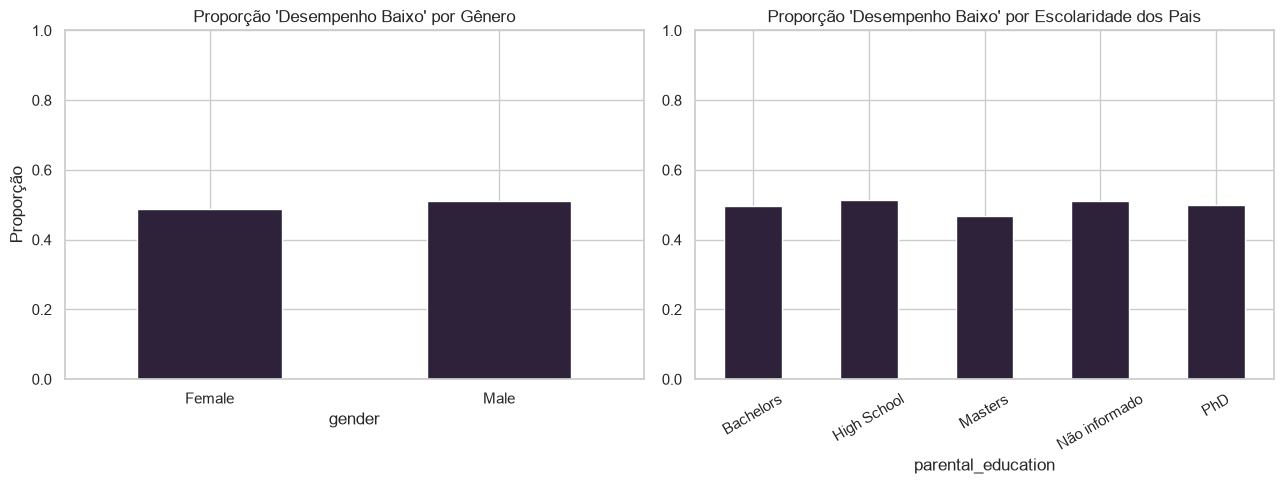

In [30]:
prop_por_genero = pd.crosstab(df["gender"], df["situacao"], normalize="index").round(3)
prop_por_educ = pd.crosstab(df["parental_education"], df["situacao"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

prop_por_genero["Desempenho Baixo"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Desempenho Baixo' por Gênero")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_educ["Desempenho Baixo"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Desempenho Baixo' por Escolaridade dos Pais")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


**Pra discutir:** a proporção de reprovação varia bastante entre gênero ou escolaridade dos pais? Se sim, isso poderia refletir um viés no processo (ex: acesso a recursos de estudo desigual) e não necessariamente uma diferença de mérito — a pergunta "a distribuição do desfecho é uniforme entre grupos?" é o ponto de partida de discussões de fairness, sem uma resposta única.

*Resposta:** Não, a proporção de "Desempenho Baixo" fica bem próxima de 50% em todos os subgrupos: por gênero, 48,8% (mulheres) vs. 51,0% (homens); por escolaridade dos pais, varia entre 46,7% e 51,4% (Masters a High School), sem nenhum grupo se destacando. Não há sinal de viés relevante nesses dois atributos — a distribuição do desfecho é bem uniforme entre grupos.

## Análise Multivariada

### Matriz de Correlação

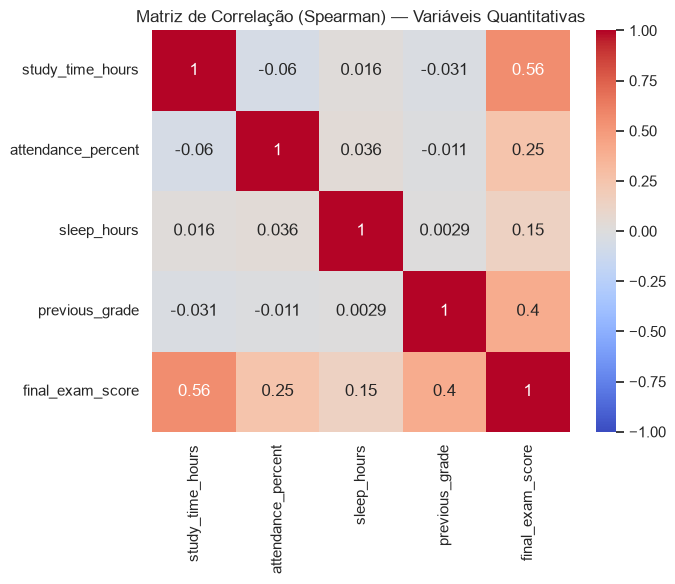

In [31]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Pra discutir:** alguma correlação chama atenção por ser forte o suficiente para sugerir redundância entre variáveis?

**Resposta:** Não, nenhuma correlação entre as variáveis preditoras chega perto de sugerir redundância — todas ficam entre -0,06 e 0,04 (study_time_hours, attendance_percent, sleep_hours e previous_grade são praticamente independentes entre si). A única correlação moderada é de cada uma com final_exam_score (destaque pra study_time_hours, 0,56), mas isso é o alvo, não redundância entre preditores. Ou seja, as variáveis parecem capturar informações distintas, sem sobreposição.

### Correlograma

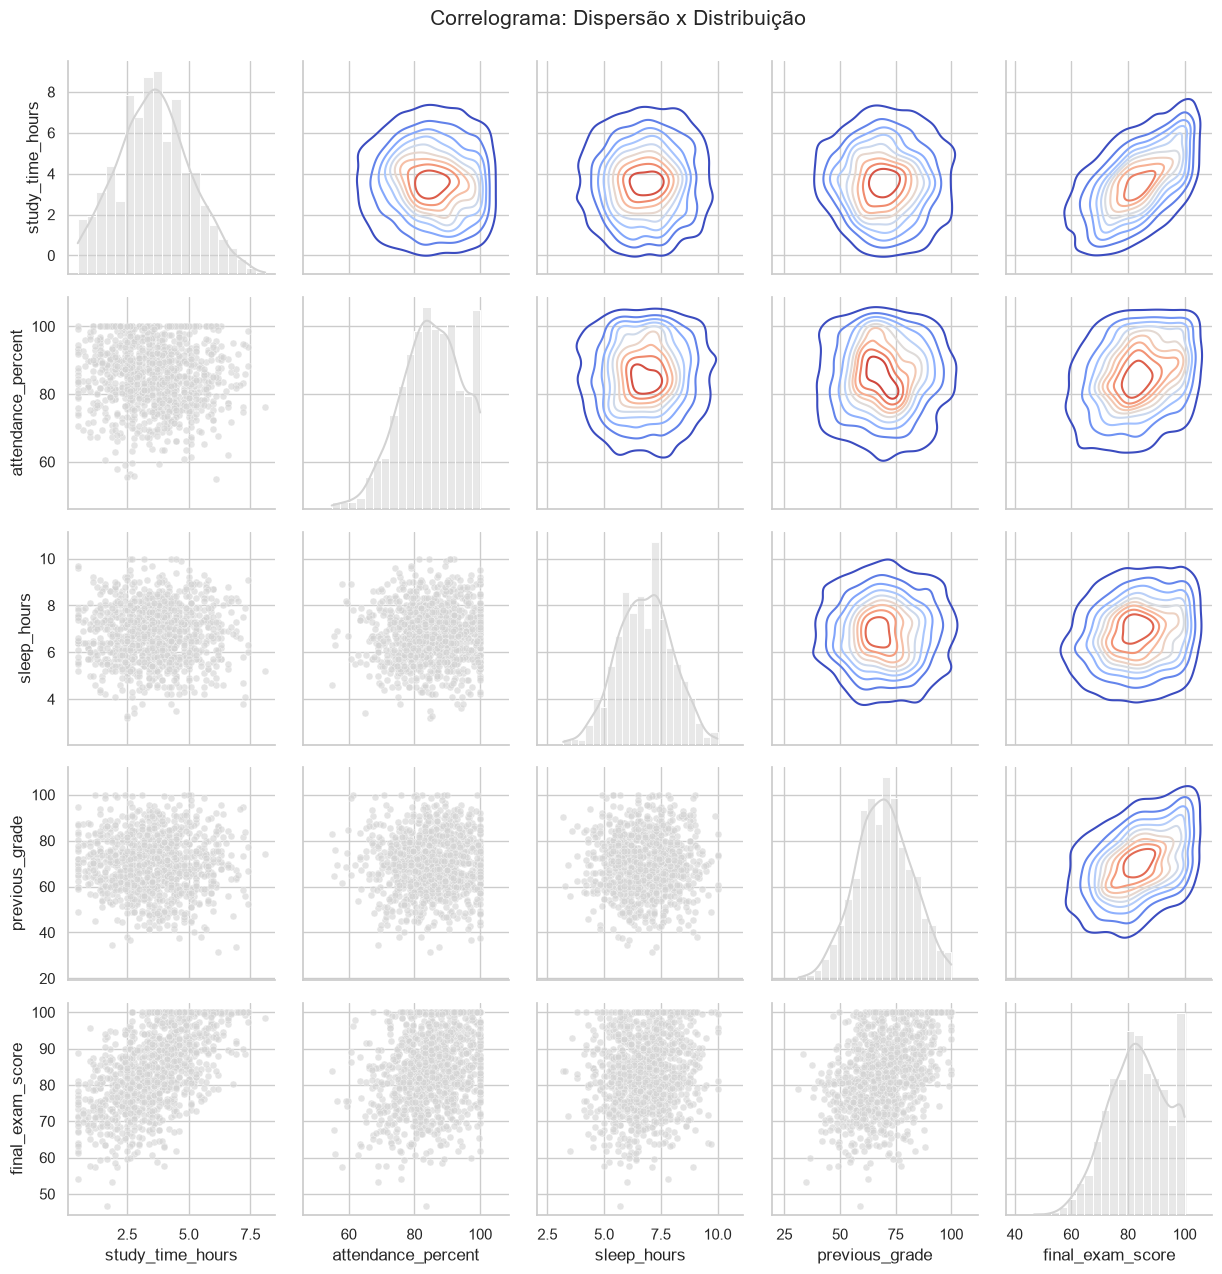

In [32]:
g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(sns.kdeplot, cmap="coolwarm")

g.fig.suptitle("Correlograma: Dispersão x Distribuição", y=1.02, fontsize=15)
plt.show()


## Síntese Final

### Principais conclusões (3 a 5 pontos)

*(Preencham depois de rodar todo o notebook e revisar as respostas às perguntas "Pra discutir" — cada conclusão deve se apoiar em algo visto acima, por exemplo: a variável mais associada a `situacao`, o quão desbalanceada é a variável-alvo, se havia dados ausentes/outliers relevantes, etc.)*

Principais conclusões:

1- study_time_hours é a variável mais associada ao desempenho (correlação de 0,56 com final_exam_score, e a que mais separa os grupos "Desempenho Alto" e "Baixo" nos boxplots), seguida de previous_grade (0,40).

2- O dataset tem poucos problemas de qualidade: só parental_education tem dados ausentes (10,2%, padrão consistente com MCAR), e os outliers encontrados em todas as variáveis quantitativas são poucos e estatisticamente legítimos, sem violar nenhum limite físico.

3- A variável-alvo original (final_grade == F) estava fortemente desbalanceada (1,2% da base) e foi substituída por um corte na mediana da nota final, resultando numa divisão praticamente perfeita (501 vs. 499).

4- Não há indício de viés relevante por gênero ou escolaridade dos pais: a proporção de "Desempenho Baixo" fica sempre próxima de 50% nesses subgrupos.

5- As variáveis preditoras (horas de estudo, frequência, sono, nota anterior) são praticamente independentes entre si (correlações entre -0,06 e 0,04), sugerindo que cada uma contribui com informação distinta pro desempenho final, sem redundância.

### Declaração de Uso de IA

Ferramenta utilizada: Claude (Anthropic).
Para o que foi aplicada: montagem do notebook, melhorias das respostas, e ferramenta de avaliação. Então sempre seguia esse fluxo: Minha interpretação -> o que o claude acha da resposta -> Ele melhorava a resposta -> eu respondia.
O que foi aceito / modificado / rejeitado e por quê: revisei todas as parte das interpretações do claude após minha resposta, conferindo contra os números reais do meu dataset, então eu fazia e ele revisava criteriosamente

(RAIZ / "data" / "raw").mkdir(parents=True, exist_ok=True)
(RAIZ / "data" / "clean").mkdir(parents=True, exist_ok=True)

df_raw.to_csv(RAIZ / "data" / "raw" / "dataset_raw.csv", index=False)
df.to_csv(RAIZ / "data" / "clean" / "dataset.csv", index=False)